# Asg 1: AlexNet and GoogleNet with Overfitting Reduction (Improved Accuracy)

This notebook implements four experiments on the Food-11 dataset:

1. AlexNet without deliberate overfitting-reduction techniques
2. AlexNet with overfitting-reduction techniques
3. GoogleNet/Inception-style CNN without deliberate overfitting-reduction techniques
4. GoogleNet/Inception-style CNN with overfitting-reduction techniques

**Architectures are unchanged. Accuracy is improved only by tuning hyperparameters:**

| Parameter | Old | New | Reason |
|---|---|---|---|
| EPOCHS | 15 | 30 | Models were still improving at epoch 15 (underfitting) |
| IMG_SIZE | 128x128 | 160x160 | AlexNet's 11x11 stride-4 conv shrank features too much at 128 |
| Learning rate (BN models) | 1e-4 | 1e-3 | 1e-4 was too slow to converge in few epochs |
| Learning rate (non-BN models) | 1e-4 | 3e-4 / 5e-4 | Faster, but still stable without BatchNorm |
| L2 strength | 1e-4 | 5e-5 | Old value dominated the loss (loss values ~4.0) |
| Weight init | glorot | He normal | Better for ReLU networks |
| Augmentation | strong | milder | Strong augmentation slowed learning of underfit models |
| EarlyStopping patience | 3 | 8 | Old patience stopped training too early |
| ReduceLROnPlateau patience | 2 | 3 | Less aggressive LR drops |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
DATASET_PATH = "/kaggle/input/datasets/trolukovich/food11-image-dataset"
TRAIN_PATH = os.path.join(DATASET_PATH, "training")
VALIDATION_PATH = os.path.join(DATASET_PATH, "validation")
TEST_PATH = os.path.join(DATASET_PATH, "evaluation")

# ---------------- Tuned hyperparameters ----------------
IMG_SIZE = (160, 160)      # was (128, 128)
BATCH_SIZE = 32
NUM_CLASSES = 11
EPOCHS = 30                # was 15

LR_BASIC_ALEX = 3e-4       # AlexNet without BatchNorm (needs a smaller LR)
LR_BASIC_GOOG = 5e-4       # GoogleNet without BatchNorm
LR_REG = 1e-3              # models with BatchNorm can use a larger LR
L2_STRENGTH = 5e-5         # was 1e-4
INIT = "he_normal"         # good initializer for ReLU
# -------------------------------------------------------

class_names = sorted([
    folder for folder in os.listdir(TRAIN_PATH)
    if os.path.isdir(os.path.join(TRAIN_PATH, folder))
])

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['Bread', 'Dairy product', 'Dessert', 'Egg', 'Fried food', 'Meat', 'Noodles-Pasta', 'Rice', 'Seafood', 'Soup', 'Vegetable-Fruit']
Number of classes: 11


## Preprocessing and Data Augmentation

Training augmentation is used to improve generalization (made milder than before so the models can learn faster). Validation and test images are only rescaled.

In [3]:
train_datagen = ImageDataGenerator(
    rescale=1.0/255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    shear_range=0.05,
    horizontal_flip=True,
    brightness_range=[0.9, 1.1]
)

validation_datagen = ImageDataGenerator(rescale=1.0/255)
test_datagen = ImageDataGenerator(rescale=1.0/255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_PATH, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=True, seed=SEED
)

validation_generator = validation_datagen.flow_from_directory(
    VALIDATION_PATH, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    TEST_PATH, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=False
)

print("Training:", train_generator.samples)
print("Validation:", validation_generator.samples)
print("Test:", test_generator.samples)

Found 9866 images belonging to 11 classes.
Found 3430 images belonging to 11 classes.
Found 3347 images belonging to 11 classes.
Training: 9866
Validation: 3430
Test: 3347


# Experiment 1 — AlexNet WITHOUT Overfitting Reduction

In [4]:
def build_alexnet_basic():
    return models.Sequential([
        layers.Input(shape=(*IMG_SIZE, 3)),
        layers.Conv2D(96, (11,11), strides=4, padding="same", activation="relu", kernel_initializer=INIT),
        layers.MaxPooling2D((3,3), strides=2),
        layers.Conv2D(256, (5,5), padding="same", activation="relu", kernel_initializer=INIT),
        layers.MaxPooling2D((3,3), strides=2),
        layers.Conv2D(384, (3,3), padding="same", activation="relu", kernel_initializer=INIT),
        layers.Conv2D(384, (3,3), padding="same", activation="relu", kernel_initializer=INIT),
        layers.Conv2D(256, (3,3), padding="same", activation="relu", kernel_initializer=INIT),
        layers.MaxPooling2D((3,3), strides=2),
        layers.Flatten(),
        layers.Dense(4096, activation="relu", kernel_initializer=INIT),
        layers.Dense(4096, activation="relu", kernel_initializer=INIT),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

alexnet_basic = build_alexnet_basic()
alexnet_basic.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_BASIC_ALEX),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
alexnet_basic.summary()

I0000 00:00:1791114691.799066      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791114691.802379      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 40, 40, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 19, 19, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 19, 19, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 9, 9, 384)      │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 9, 9, 384)      │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 9, 9, 256)      │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 11)             │        45,067 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,354,891 (142.50 MB)

 Trainable params: 37,354,891 (142.50 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history_alex_basic = alexnet_basic.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator
)

Epoch 1/30
  1/309 ━━━━━━━━━━━━━━━━━━━━ 42:16 8s/step - accuracy: 0.0312 - loss: 3.0326

I0000 00:00:1791114702.624373      91 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


309/309 ━━━━━━━━━━━━━━━━━━━━ 172s 532ms/step - accuracy: 0.2204 - loss: 2.2665 - val_accuracy: 0.3003 - val_loss: 1.9975
Epoch 2/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 104s 337ms/step - accuracy: 0.3284 - loss: 1.9201 - val_accuracy: 0.3845 - val_loss: 1.7528
Epoch 3/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 99s 320ms/step - accuracy: 0.3890 - loss: 1.7624 - val_accuracy: 0.4294 - val_loss: 1.6307
Epoch 4/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 97s 315ms/step - accuracy: 0.4389 - loss: 1.6315 - val_accuracy: 0.4781 - val_loss: 1.5259
Epoch 5/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 98s 317ms/step - accuracy: 0.4785 - loss: 1.5149 - val_accuracy: 0.5128 - val_loss: 1.4328
Epoch 6/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 101s 327ms/step - accuracy: 0.5092 - loss: 1.4246 - val_accuracy: 0.5315 - val_loss: 1.3870
Epoch 7/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 98s 317ms/step - accuracy: 0.5366 - loss: 1.3416 - val_accuracy: 0.5271 - val_loss: 1.4195
Epoch 8/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 96s 310ms/step - accuracy: 0.5538 - loss: 1.2702 - 

In [6]:
alex_basic_test_loss, alex_basic_test_accuracy = alexnet_basic.evaluate(
    test_generator, verbose=1
)

print(f"AlexNet WITHOUT overfitting reduction - Test Loss: {alex_basic_test_loss:.4f}")
print(f"AlexNet WITHOUT overfitting reduction - Test Accuracy: {alex_basic_test_accuracy*100:.2f}%")

105/105 ━━━━━━━━━━━━━━━━━━━━ 31s 293ms/step - accuracy: 0.6421 - loss: 1.4148
AlexNet WITHOUT overfitting reduction - Test Loss: 1.4148
AlexNet WITHOUT overfitting reduction - Test Accuracy: 64.21%


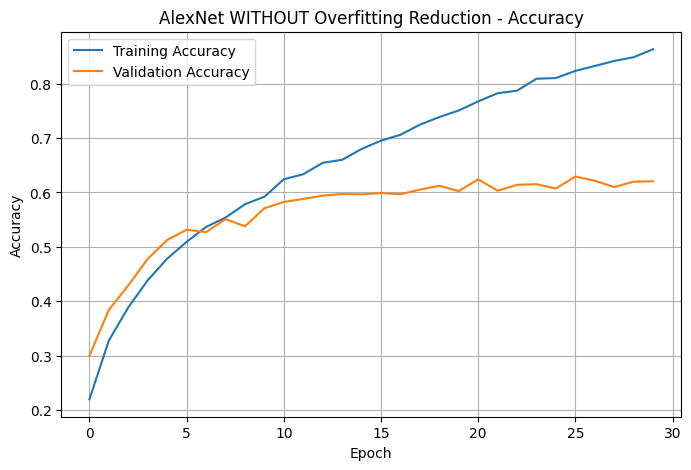

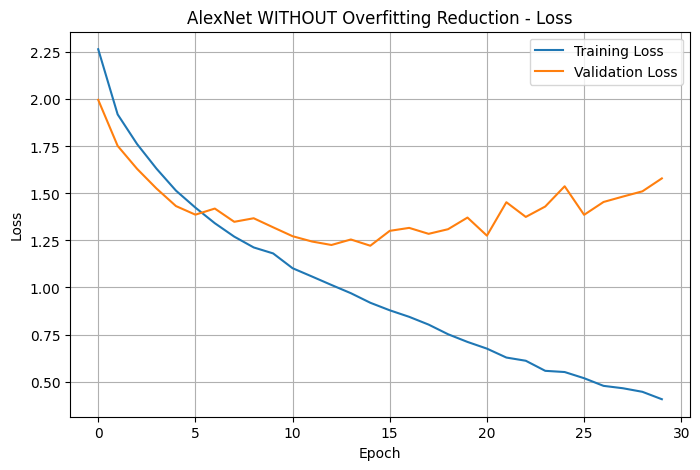

In [7]:
def plot_history(history, title):
    plt.figure(figsize=(8,5))
    plt.plot(history.history["accuracy"], label="Training Accuracy")
    plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
    plt.title(title + " - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(8,5))
    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.title(title + " - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

from sklearn.metrics import confusion_matrix, classification_report

def evaluate_with_confusion(model, generator, title):
    generator.reset()
    probs = model.predict(generator, verbose=1)
    y_pred = np.argmax(probs, axis=1)
    y_true = generator.classes
    labels = list(generator.class_indices.keys())

    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(20, 8))
    for ax, data, fmt, sub in [(axes[0], cm, "d", "Counts"),
                               (axes[1], cm_norm, ".2f", "Normalized (row %)")]:
        im = ax.imshow(data, cmap="Blues")
        ax.set_title(f"{title}\nConfusion Matrix - {sub}")
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("True label")
        ax.set_xticks(range(len(labels)))
        ax.set_yticks(range(len(labels)))
        ax.set_xticklabels(labels, rotation=45, ha="right")
        ax.set_yticklabels(labels)
        thresh = data.max() / 2.0
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                val = format(data[i, j], fmt)
                ax.text(j, i, val, ha="center", va="center", fontsize=8,
                        color="white" if data[i, j] > thresh else "black")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

    print(f"Classification Report - {title}")
    print(classification_report(y_true, y_pred, target_names=labels, digits=3))
    return cm, y_true, y_pred

plot_history(history_alex_basic, "AlexNet WITHOUT Overfitting Reduction")

105/105 ━━━━━━━━━━━━━━━━━━━━ 12s 113ms/step


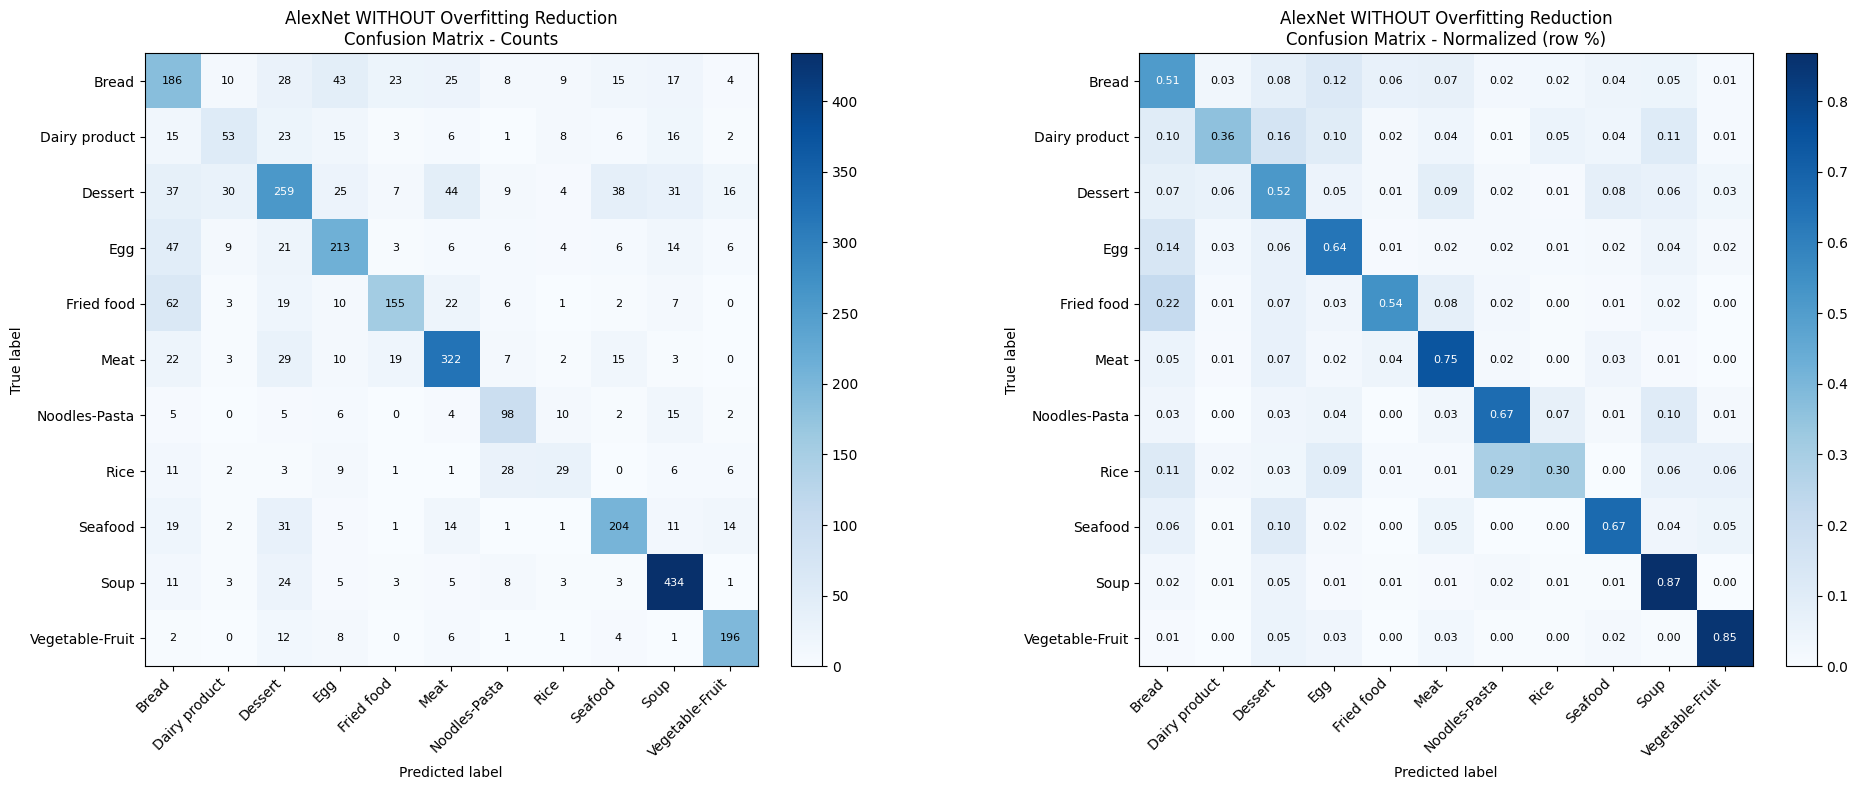

Classification Report - AlexNet WITHOUT Overfitting Reduction
                 precision    recall  f1-score   support

          Bread      0.446     0.505     0.474       368
  Dairy product      0.461     0.358     0.403       148
        Dessert      0.570     0.518     0.543       500
            Egg      0.610     0.636     0.623       335
     Fried food      0.721     0.540     0.618       287
           Meat      0.708     0.745     0.726       432
  Noodles-Pasta      0.566     0.667     0.613       147
           Rice      0.403     0.302     0.345        96
        Seafood      0.692     0.673     0.682       303
           Soup      0.782     0.868     0.823       500
Vegetable-Fruit      0.794     0.848     0.820       231

       accuracy                          0.642      3347
      macro avg      0.614     0.606     0.606      3347
   weighted avg      0.640     0.642     0.638      3347



In [8]:
cm_alex_basic, y_true, y_pred_alex_basic = evaluate_with_confusion(
    alexnet_basic, test_generator, "AlexNet WITHOUT Overfitting Reduction"
)

# Experiment 2 — AlexNet WITH Overfitting Reduction

Techniques: data augmentation, batch normalization, L2 regularization, dropout, early stopping, and ReduceLROnPlateau.

In [9]:
def build_alexnet_regularized():
    reg = regularizers.l2(L2_STRENGTH)

    return models.Sequential([
        layers.Input(shape=(*IMG_SIZE, 3)),

        layers.Conv2D(96, (11,11), strides=4, padding="same",
                      activation="relu", kernel_regularizer=reg, kernel_initializer=INIT),
        layers.BatchNormalization(),
        layers.MaxPooling2D((3,3), strides=2),

        layers.Conv2D(256, (5,5), padding="same",
                      activation="relu", kernel_regularizer=reg, kernel_initializer=INIT),
        layers.BatchNormalization(),
        layers.MaxPooling2D((3,3), strides=2),

        layers.Conv2D(384, (3,3), padding="same",
                      activation="relu", kernel_regularizer=reg, kernel_initializer=INIT),
        layers.BatchNormalization(),

        layers.Conv2D(384, (3,3), padding="same",
                      activation="relu", kernel_regularizer=reg, kernel_initializer=INIT),
        layers.BatchNormalization(),

        layers.Conv2D(256, (3,3), padding="same",
                      activation="relu", kernel_regularizer=reg, kernel_initializer=INIT),
        layers.BatchNormalization(),
        layers.MaxPooling2D((3,3), strides=2),

        layers.Flatten(),

        layers.Dense(4096, activation="relu", kernel_regularizer=reg, kernel_initializer=INIT),
        layers.BatchNormalization(),
        layers.Dropout(0.5),

        layers.Dense(4096, activation="relu", kernel_regularizer=reg, kernel_initializer=INIT),
        layers.BatchNormalization(),
        layers.Dropout(0.5),

        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

alexnet_regularized = build_alexnet_regularized()
alexnet_regularized.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_REG),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
alexnet_regularized.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 40, 40, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 40, 40, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 19, 19, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 19, 19, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 19, 19, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 9, 9, 384)      │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 9, 9, 384)      │         1,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 9, 9, 384)      │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 9, 9, 384)      │         1,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 9, 9, 256)      │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 9, 9, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 4096)           │        16,384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 4096)           │        16,384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 11)             │        45,067 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 37,393,163 (142.64 MB)

 Trainable params: 37,374,027 (142.57 MB)

 Non-trainable params: 19,136 (74.75 KB)

In [10]:
early_stopping_alex = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_alex = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history_alex_regularized = alexnet_regularized.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator,
    callbacks=[early_stopping_alex, reduce_lr_alex]
)

Epoch 1/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 115s 338ms/step - accuracy: 0.2113 - loss: 4.3692 - val_accuracy: 0.1936 - val_loss: 6.2408 - learning_rate: 0.0010
Epoch 2/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 102s 329ms/step - accuracy: 0.2547 - loss: 3.8754 - val_accuracy: 0.1644 - val_loss: 6.1077 - learning_rate: 0.0010
Epoch 3/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 98s 317ms/step - accuracy: 0.2676 - loss: 3.9668 - val_accuracy: 0.1936 - val_loss: 9.8682 - learning_rate: 0.0010
Epoch 4/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 98s 318ms/step - accuracy: 0.2896 - loss: 3.8124 - val_accuracy: 0.1974 - val_loss: 7.0297 - learning_rate: 0.0010
Epoch 5/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 100s 322ms/step - accuracy: 0.2881 - loss: 3.8437 - val_accuracy: 0.2889 - val_loss: 4.6381 - learning_rate: 0.0010
Epoch 6/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 101s 327ms/step - accuracy: 0.2979 - loss: 3.7809 - val_accuracy: 0.2000 - val_loss: 19.5565 - learning_rate: 0.0010
Epoch 7/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 99s 321ms/step - accuracy

105/105 ━━━━━━━━━━━━━━━━━━━━ 16s 148ms/step - accuracy: 0.5016 - loss: 2.5457
AlexNet WITH overfitting reduction - Test Loss: 2.5457
AlexNet WITH overfitting reduction - Test Accuracy: 50.16%


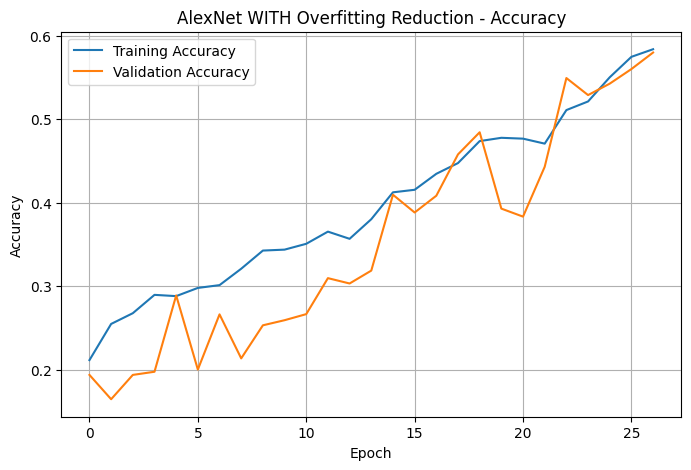

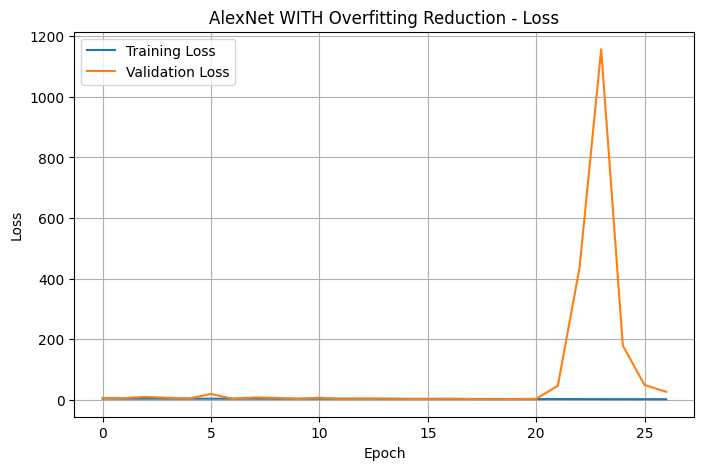

In [11]:
alex_reg_test_loss, alex_reg_test_accuracy = alexnet_regularized.evaluate(
    test_generator, verbose=1
)

print(f"AlexNet WITH overfitting reduction - Test Loss: {alex_reg_test_loss:.4f}")
print(f"AlexNet WITH overfitting reduction - Test Accuracy: {alex_reg_test_accuracy*100:.2f}%")

plot_history(history_alex_regularized, "AlexNet WITH Overfitting Reduction")

105/105 ━━━━━━━━━━━━━━━━━━━━ 14s 123ms/step


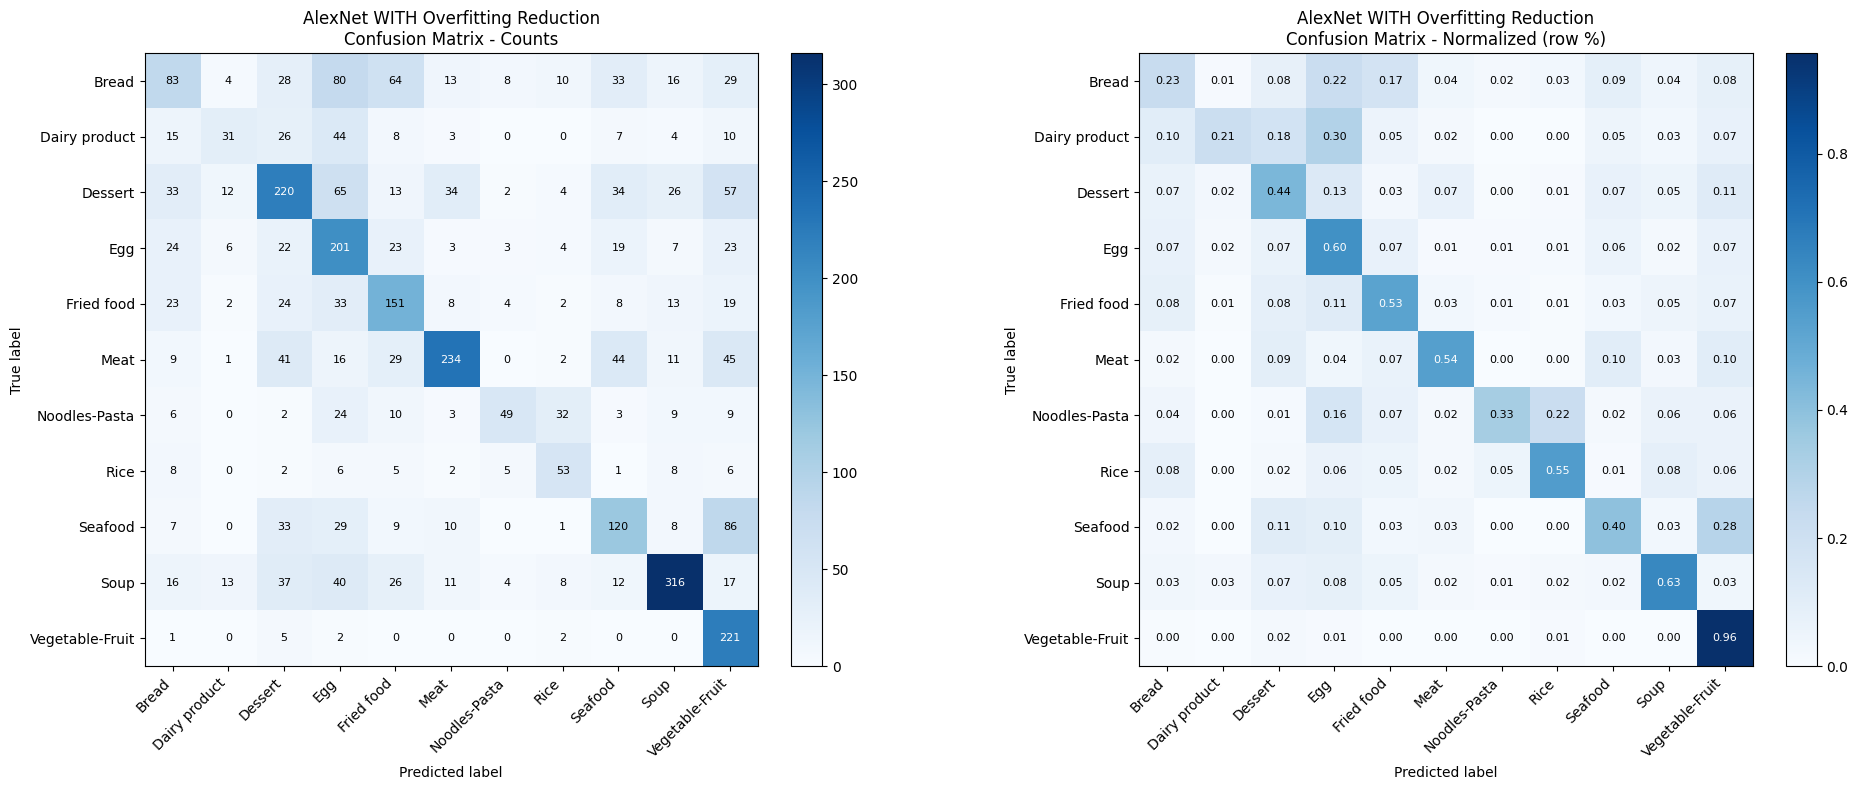

Classification Report - AlexNet WITH Overfitting Reduction
                 precision    recall  f1-score   support

          Bread      0.369     0.226     0.280       368
  Dairy product      0.449     0.209     0.286       148
        Dessert      0.500     0.440     0.468       500
            Egg      0.372     0.600     0.459       335
     Fried food      0.447     0.526     0.483       287
           Meat      0.729     0.542     0.622       432
  Noodles-Pasta      0.653     0.333     0.441       147
           Rice      0.449     0.552     0.495        96
        Seafood      0.427     0.396     0.411       303
           Soup      0.756     0.632     0.688       500
Vegetable-Fruit      0.423     0.957     0.587       231

       accuracy                          0.502      3347
      macro avg      0.507     0.492     0.475      3347
   weighted avg      0.527     0.502     0.495      3347



In [12]:
cm_alex_reg, _, y_pred_alex_reg = evaluate_with_confusion(
    alexnet_regularized, test_generator, "AlexNet WITH Overfitting Reduction"
)

# Experiment 3 — GoogleNet / Inception-style CNN WITHOUT Overfitting Reduction

This is an Inception-style implementation based on the core GoogleNet idea of parallel convolution branches.

In [13]:
def inception_block_basic(x, filters):
    f1, f3r, f3, f5r, f5, pool = filters

    b1 = layers.Conv2D(f1, 1, padding="same", activation="relu", kernel_initializer=INIT)(x)

    b2 = layers.Conv2D(f3r, 1, padding="same", activation="relu", kernel_initializer=INIT)(x)
    b2 = layers.Conv2D(f3, 3, padding="same", activation="relu", kernel_initializer=INIT)(b2)

    b3 = layers.Conv2D(f5r, 1, padding="same", activation="relu", kernel_initializer=INIT)(x)
    b3 = layers.Conv2D(f5, 5, padding="same", activation="relu", kernel_initializer=INIT)(b3)

    b4 = layers.MaxPooling2D(3, strides=1, padding="same")(x)
    b4 = layers.Conv2D(pool, 1, padding="same", activation="relu", kernel_initializer=INIT)(b4)

    return layers.Concatenate()([b1, b2, b3, b4])


def build_googlenet_basic():
    inp = layers.Input(shape=(*IMG_SIZE, 3))

    x = layers.Conv2D(64, 7, strides=2, padding="same", activation="relu", kernel_initializer=INIT)(inp)
    x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

    x = layers.Conv2D(64, 1, padding="same", activation="relu", kernel_initializer=INIT)(x)
    x = layers.Conv2D(192, 3, padding="same", activation="relu", kernel_initializer=INIT)(x)
    x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

    x = inception_block_basic(x, (64, 96, 128, 16, 32, 32))
    x = inception_block_basic(x, (128, 128, 192, 32, 96, 64))

    x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

    x = inception_block_basic(x, (192, 96, 208, 16, 48, 64))
    x = inception_block_basic(x, (160, 112, 224, 24, 64, 64))

    x = layers.GlobalAveragePooling2D()(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    return models.Model(inp, out, name="GoogleNet_Basic")


googlenet_basic = build_googlenet_basic()
googlenet_basic.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_BASIC_GOOG),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
googlenet_basic.summary()

Model: "GoogleNet_Basic"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 160, 160,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 80, 80,    │      9,472 │ input_layer_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 40, 40,    │          0 │ conv2d_10[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 40, 40,    │      4,160 │ max_pooling2d_6[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 40, 40,    │    110,784 │ conv2d_11[0][0]   │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 20, 20,    │          0 │ conv2d_12[0][0]   │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 20, 20,    │     18,528 │ max_pooling2d_7[… │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 20, 20,    │      3,088 │ max_pooling2d_7[… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 20, 20,    │          0 │ max_pooling2d_7[… │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 20, 20,    │     12,352 │ max_pooling2d_7[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 20, 20,    │    110,720 │ conv2d_14[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 20, 20,    │     12,832 │ conv2d_16[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 20, 20,    │      6,176 │ max_pooling2d_8[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 20, 20,    │          0 │ conv2d_13[0][0],  │
│ (Concatenate)       │ 256)              │            │ conv2d_15[0][0],  │
│                     │                   │            │ conv2d_17[0][0],  │
│                     │                   │            │ conv2d_18[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 20, 20,    │     32,896 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 20, 20,    │      8,224 │ concatenate[0][0] │
│                     │ 32)               │            │                 

 Total params: 1,507,827 (5.75 MB)

 Trainable params: 1,507,827 (5.75 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
history_googlenet_basic = googlenet_basic.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator
)

Epoch 1/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 145s 403ms/step - accuracy: 0.2371 - loss: 2.1366 - val_accuracy: 0.3289 - val_loss: 1.9023
Epoch 2/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 107s 346ms/step - accuracy: 0.3431 - loss: 1.8617 - val_accuracy: 0.4090 - val_loss: 1.7292
Epoch 3/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 108s 348ms/step - accuracy: 0.4177 - loss: 1.6615 - val_accuracy: 0.4706 - val_loss: 1.5653
Epoch 4/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 107s 345ms/step - accuracy: 0.4696 - loss: 1.5348 - val_accuracy: 0.5058 - val_loss: 1.4900
Epoch 5/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 107s 346ms/step - accuracy: 0.5248 - loss: 1.4011 - val_accuracy: 0.5012 - val_loss: 1.5138
Epoch 6/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 162s 524ms/step - accuracy: 0.5436 - loss: 1.3498 - val_accuracy: 0.5627 - val_loss: 1.3335
Epoch 7/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 204s 662ms/step - accuracy: 0.5637 - loss: 1.2601 - val_accuracy: 0.5805 - val_loss: 1.2341
Epoch 8/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 222s 719ms/step - accuracy: 0.5942 -

105/105 ━━━━━━━━━━━━━━━━━━━━ 16s 156ms/step - accuracy: 0.7162 - loss: 0.9976
GoogleNet WITHOUT overfitting reduction - Test Loss: 0.9976
GoogleNet WITHOUT overfitting reduction - Test Accuracy: 71.62%


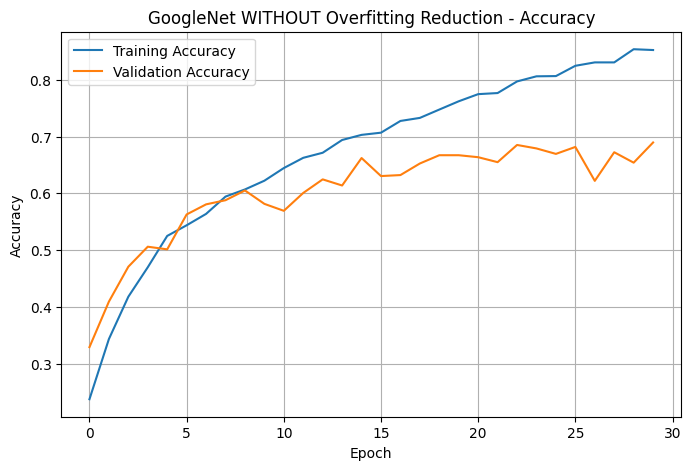

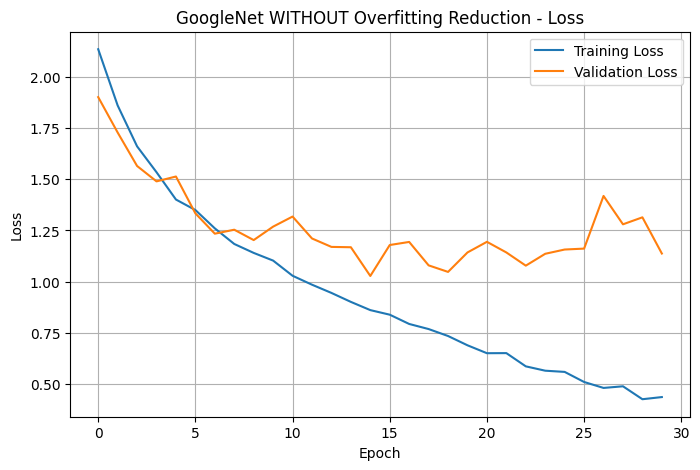

In [15]:
goog_basic_test_loss, goog_basic_test_accuracy = googlenet_basic.evaluate(
    test_generator, verbose=1
)

print(f"GoogleNet WITHOUT overfitting reduction - Test Loss: {goog_basic_test_loss:.4f}")
print(f"GoogleNet WITHOUT overfitting reduction - Test Accuracy: {goog_basic_test_accuracy*100:.2f}%")

plot_history(history_googlenet_basic, "GoogleNet WITHOUT Overfitting Reduction")

105/105 ━━━━━━━━━━━━━━━━━━━━ 15s 123ms/step


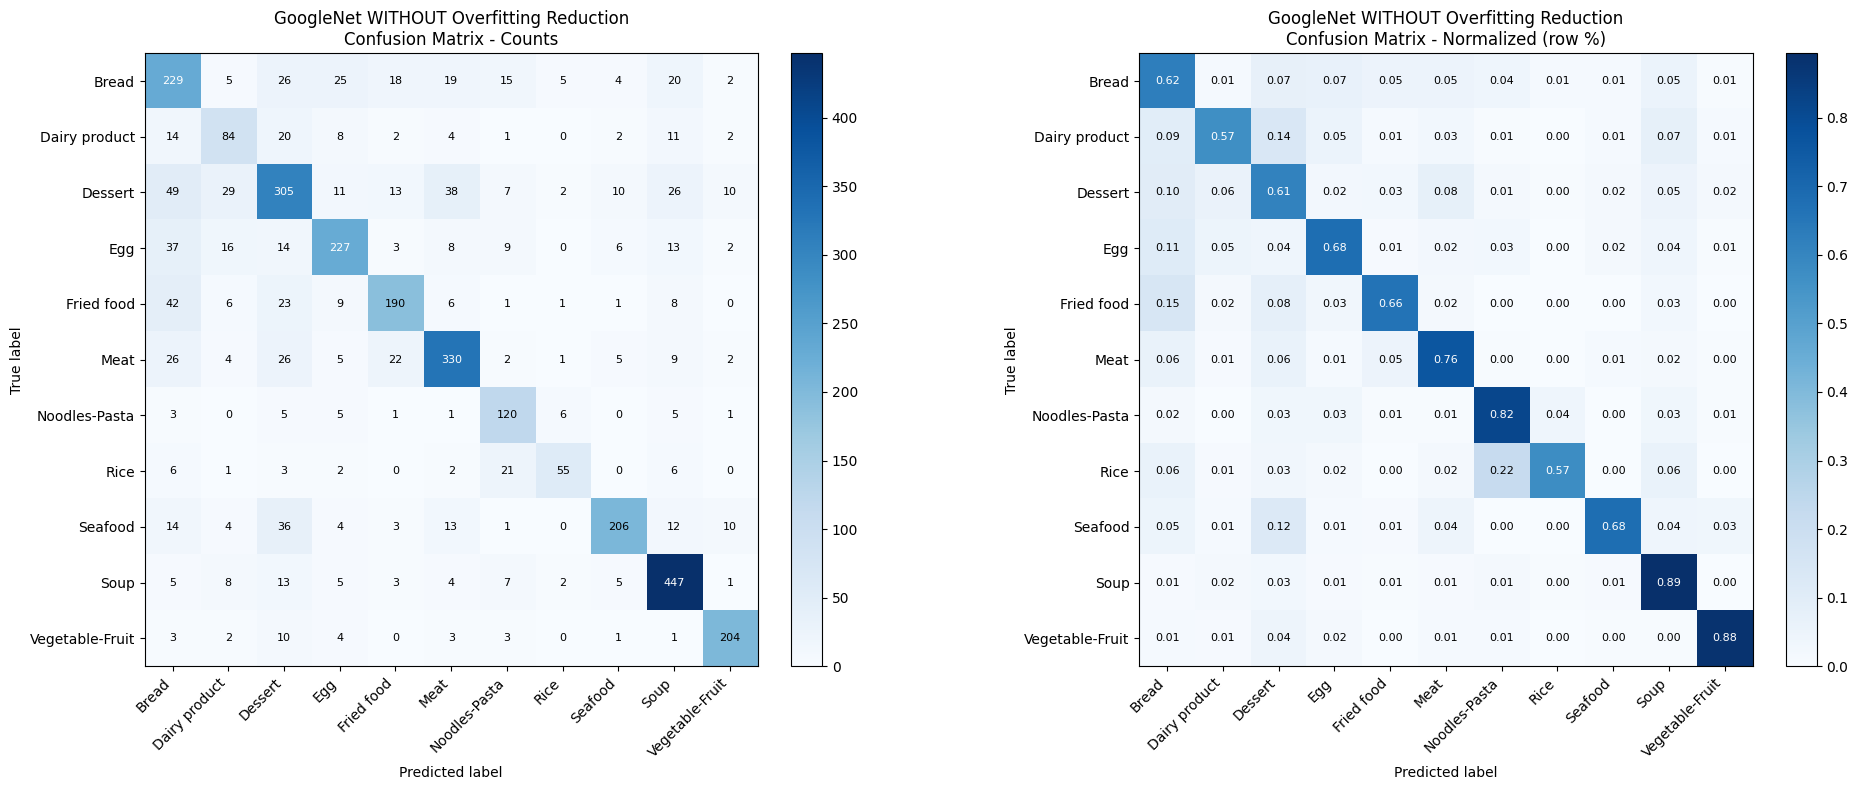

Classification Report - GoogleNet WITHOUT Overfitting Reduction
                 precision    recall  f1-score   support

          Bread      0.535     0.622     0.575       368
  Dairy product      0.528     0.568     0.547       148
        Dessert      0.634     0.610     0.622       500
            Egg      0.744     0.678     0.709       335
     Fried food      0.745     0.662     0.701       287
           Meat      0.771     0.764     0.767       432
  Noodles-Pasta      0.642     0.816     0.719       147
           Rice      0.764     0.573     0.655        96
        Seafood      0.858     0.680     0.759       303
           Soup      0.801     0.894     0.845       500
Vegetable-Fruit      0.872     0.883     0.877       231

       accuracy                          0.716      3347
      macro avg      0.718     0.705     0.707      3347
   weighted avg      0.722     0.716     0.716      3347



In [16]:
cm_goog_basic, _, y_pred_goog_basic = evaluate_with_confusion(
    googlenet_basic, test_generator, "GoogleNet WITHOUT Overfitting Reduction"
)

# Experiment 4 — GoogleNet / Inception-style CNN WITH Overfitting Reduction

In [17]:
def inception_block_regularized(x, filters, reg):
    f1, f3r, f3, f5r, f5, pool = filters

    b1 = layers.Conv2D(f1, 1, padding="same", activation="relu",
                       kernel_regularizer=reg, kernel_initializer=INIT)(x)
    b1 = layers.BatchNormalization()(b1)

    b2 = layers.Conv2D(f3r, 1, padding="same", activation="relu",
                       kernel_regularizer=reg, kernel_initializer=INIT)(x)
    b2 = layers.BatchNormalization()(b2)
    b2 = layers.Conv2D(f3, 3, padding="same", activation="relu",
                       kernel_regularizer=reg, kernel_initializer=INIT)(b2)
    b2 = layers.BatchNormalization()(b2)

    b3 = layers.Conv2D(f5r, 1, padding="same", activation="relu",
                       kernel_regularizer=reg, kernel_initializer=INIT)(x)
    b3 = layers.BatchNormalization()(b3)
    b3 = layers.Conv2D(f5, 5, padding="same", activation="relu",
                       kernel_regularizer=reg, kernel_initializer=INIT)(b3)
    b3 = layers.BatchNormalization()(b3)

    b4 = layers.MaxPooling2D(3, strides=1, padding="same")(x)
    b4 = layers.Conv2D(pool, 1, padding="same", activation="relu",
                       kernel_regularizer=reg, kernel_initializer=INIT)(b4)
    b4 = layers.BatchNormalization()(b4)

    return layers.Concatenate()([b1, b2, b3, b4])


def build_googlenet_regularized():
    reg = regularizers.l2(L2_STRENGTH)

    inp = layers.Input(shape=(*IMG_SIZE, 3))

    x = layers.Conv2D(64, 7, strides=2, padding="same",
                      activation="relu", kernel_regularizer=reg, kernel_initializer=INIT)(inp)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

    x = layers.Conv2D(64, 1, padding="same",
                      activation="relu", kernel_regularizer=reg, kernel_initializer=INIT)(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv2D(192, 3, padding="same",
                      activation="relu", kernel_regularizer=reg, kernel_initializer=INIT)(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

    x = inception_block_regularized(x, (64, 96, 128, 16, 32, 32), reg)
    x = inception_block_regularized(x, (128, 128, 192, 32, 96, 64), reg)

    x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

    x = inception_block_regularized(x, (192, 96, 208, 16, 48, 64), reg)
    x = inception_block_regularized(x, (160, 112, 224, 24, 64, 64), reg)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)

    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    return models.Model(inp, out, name="GoogleNet_Regularized")


googlenet_regularized = build_googlenet_regularized()
googlenet_regularized.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_REG),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
googlenet_regularized.summary()

Model: "GoogleNet_Regularized"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 160, 160,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_37 (Conv2D)  │ (None, 80, 80,    │      9,472 │ input_layer_3[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 80, 80,    │        256 │ conv2d_37[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_13    │ (None, 40, 40,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_38 (Conv2D)  │ (None, 40, 40,    │      4,160 │ max_pooling2d_13… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 40, 40,    │        256 │ conv2d_38[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_39 (Conv2D)  │ (None, 40, 40,    │    110,784 │ batch_normalizat… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 40, 40,    │        768 │ conv2d_39[0][0]   │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_14    │ (None, 20, 20,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_41 (Conv2D)  │ (None, 20, 20,    │     18,528 │ max_pooling2d_14… │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_43 (Conv2D)  │ (None, 20, 20,    │      3,088 │ max_pooling2d_14… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 20, 20,    │        384 │ conv2d_41[0][0]   │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 20, 20,    │         64 │ conv2d_43[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_15    │ (None, 20, 20,    │          0 │ max_pooling2d_14… │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_40 (Conv2D)  │ (None, 20, 20,    │     12,352 │ max_pooling2d_14… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_42 (Conv2D)  │ (None, 20, 20,    │    110,720 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_44 (Conv2D)  │ (None, 20, 20,    │     12,832 │ batch_normalizat

 Total params: 1,518,227 (5.79 MB)

 Trainable params: 1,513,027 (5.77 MB)

 Non-trainable params: 5,200 (20.31 KB)

In [18]:
early_stopping_goog = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_goog = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history_googlenet_regularized = googlenet_regularized.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator,
    callbacks=[early_stopping_goog, reduce_lr_goog]
)

Epoch 1/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 164s 420ms/step - accuracy: 0.3549 - loss: 2.1886 - val_accuracy: 0.2636 - val_loss: 2.9746 - learning_rate: 0.0010
Epoch 2/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 104s 337ms/step - accuracy: 0.4682 - loss: 1.8215 - val_accuracy: 0.4125 - val_loss: 2.1124 - learning_rate: 0.0010
Epoch 3/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 103s 333ms/step - accuracy: 0.5223 - loss: 1.6567 - val_accuracy: 0.3671 - val_loss: 2.5613 - learning_rate: 0.0010
Epoch 4/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 100s 322ms/step - accuracy: 0.5588 - loss: 1.5464 - val_accuracy: 0.4603 - val_loss: 1.9161 - learning_rate: 0.0010
Epoch 5/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 101s 325ms/step - accuracy: 0.5974 - loss: 1.4356 - val_accuracy: 0.5149 - val_loss: 1.7783 - learning_rate: 0.0010
Epoch 6/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 98s 317ms/step - accuracy: 0.6196 - loss: 1.3704 - val_accuracy: 0.5015 - val_loss: 1.8675 - learning_rate: 0.0010
Epoch 7/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 97s 315ms/step - accuracy

105/105 ━━━━━━━━━━━━━━━━━━━━ 16s 151ms/step - accuracy: 0.7938 - loss: 0.9723
GoogleNet WITH overfitting reduction - Test Loss: 0.9723
GoogleNet WITH overfitting reduction - Test Accuracy: 79.38%


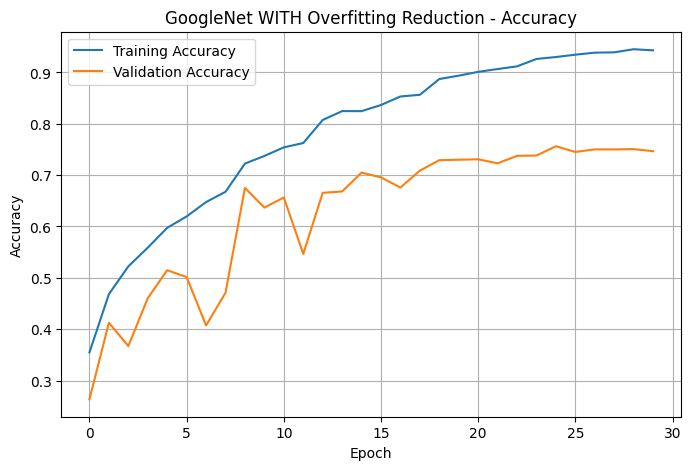

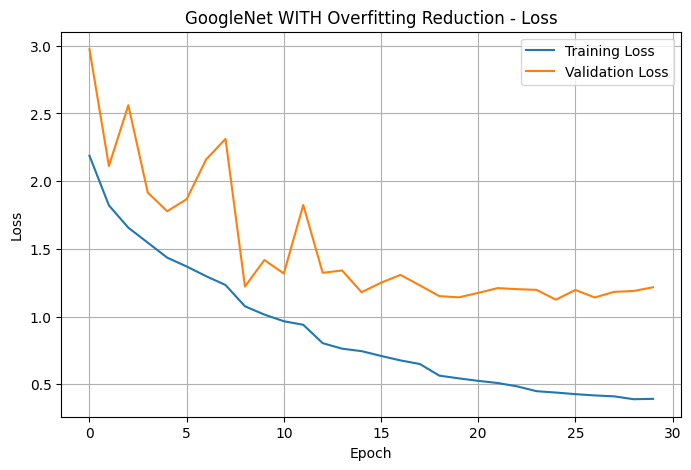

In [19]:
goog_reg_test_loss, goog_reg_test_accuracy = googlenet_regularized.evaluate(
    test_generator, verbose=1
)

print(f"GoogleNet WITH overfitting reduction - Test Loss: {goog_reg_test_loss:.4f}")
print(f"GoogleNet WITH overfitting reduction - Test Accuracy: {goog_reg_test_accuracy*100:.2f}%")

plot_history(history_googlenet_regularized, "GoogleNet WITH Overfitting Reduction")

105/105 ━━━━━━━━━━━━━━━━━━━━ 16s 128ms/step


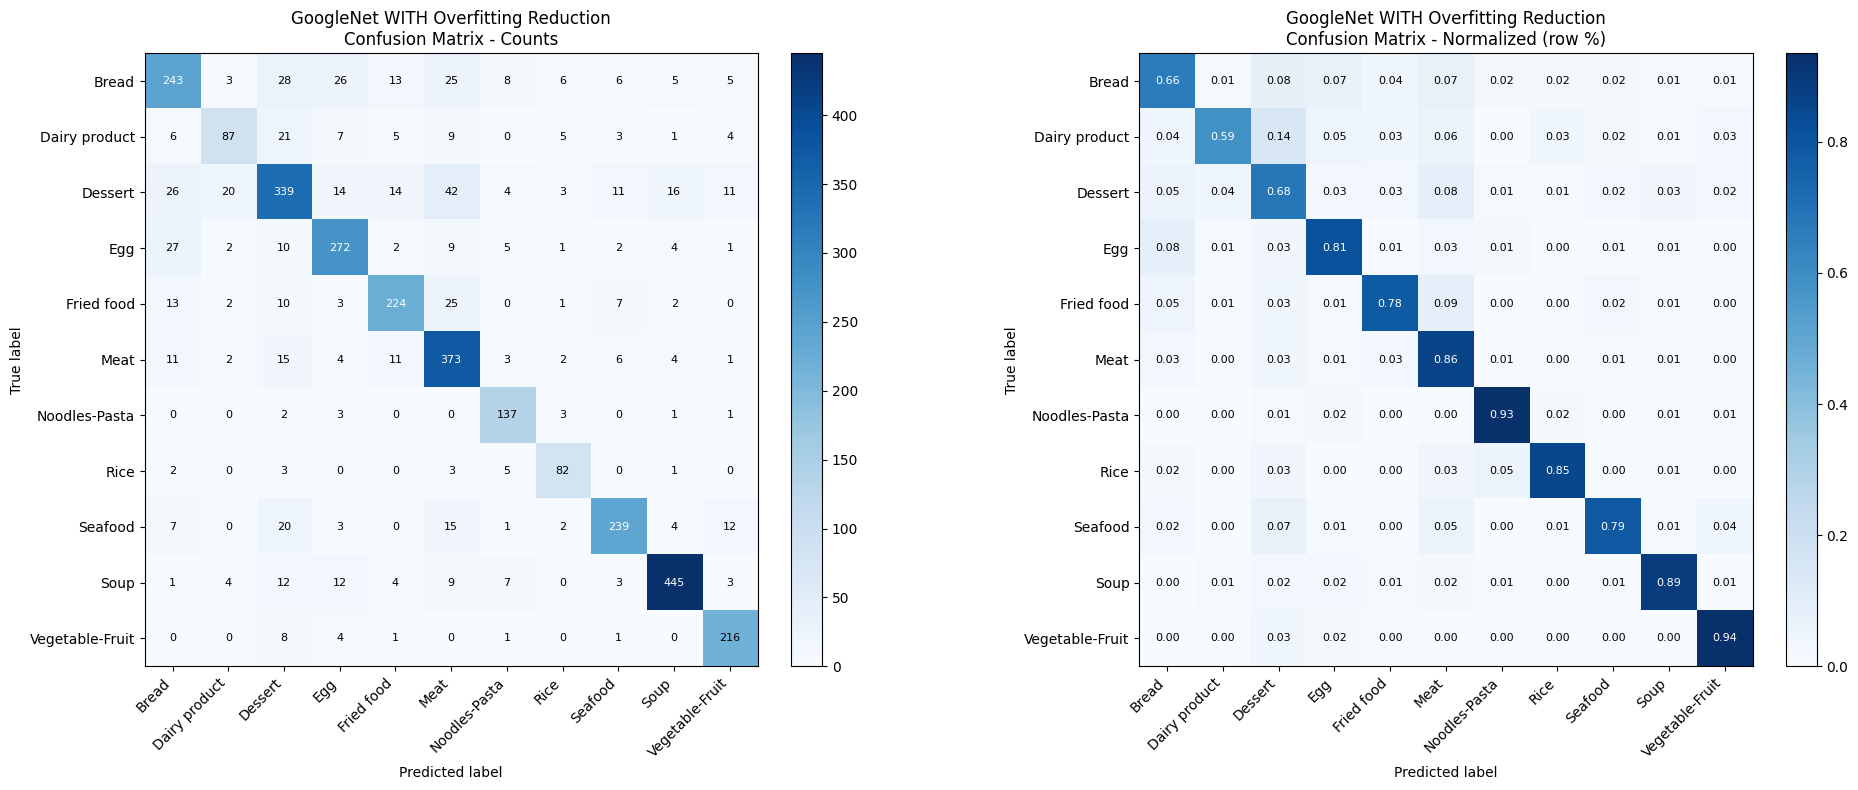

Classification Report - GoogleNet WITH Overfitting Reduction
                 precision    recall  f1-score   support

          Bread      0.723     0.660     0.690       368
  Dairy product      0.725     0.588     0.649       148
        Dessert      0.724     0.678     0.700       500
            Egg      0.782     0.812     0.796       335
     Fried food      0.818     0.780     0.799       287
           Meat      0.731     0.863     0.792       432
  Noodles-Pasta      0.801     0.932     0.862       147
           Rice      0.781     0.854     0.816        96
        Seafood      0.860     0.789     0.823       303
           Soup      0.921     0.890     0.905       500
Vegetable-Fruit      0.850     0.935     0.891       231

       accuracy                          0.794      3347
      macro avg      0.792     0.798     0.793      3347
   weighted avg      0.794     0.794     0.792      3347



In [20]:
cm_goog_reg, _, y_pred_goog_reg = evaluate_with_confusion(
    googlenet_regularized, test_generator, "GoogleNet WITH Overfitting Reduction"
)

# Final Comparison

The table uses the actual measured results from all four experiments. Accuracy values are not hard-coded.

In [21]:
def final_train_accuracy(history):
    return history.history["accuracy"][-1] * 100

def final_val_accuracy(history):
    return history.history["val_accuracy"][-1] * 100

results = pd.DataFrame([
    [
        "AlexNet", "Without Overfitting Reduction",
        final_train_accuracy(history_alex_basic),
        final_val_accuracy(history_alex_basic),
        alex_basic_test_accuracy * 100
    ],
    [
        "AlexNet", "With Overfitting Reduction",
        final_train_accuracy(history_alex_regularized),
        final_val_accuracy(history_alex_regularized),
        alex_reg_test_accuracy * 100
    ],
    [
        "GoogleNet", "Without Overfitting Reduction",
        final_train_accuracy(history_googlenet_basic),
        final_val_accuracy(history_googlenet_basic),
        goog_basic_test_accuracy * 100
    ],
    [
        "GoogleNet", "With Overfitting Reduction",
        final_train_accuracy(history_googlenet_regularized),
        final_val_accuracy(history_googlenet_regularized),
        goog_reg_test_accuracy * 100
    ]
], columns=[
    "Model", "Technique",
    "Final Training Accuracy (%)",
    "Final Validation Accuracy (%)",
    "Test Accuracy (%)"
])

display(results.round(2))

,Model,Technique,Final Training Accuracy (%),Final Validation Accuracy (%),Test Accuracy (%)
0,AlexNet,Without Overfitting Reduction,86.30,62.04,64.21
1,AlexNet,With Overfitting Reduction,58.41,58.02,50.16
2,GoogleNet,Without Overfitting Reduction,85.24,68.95,71.62
3,GoogleNet,With Overfitting Reduction,94.30,74.66,79.38


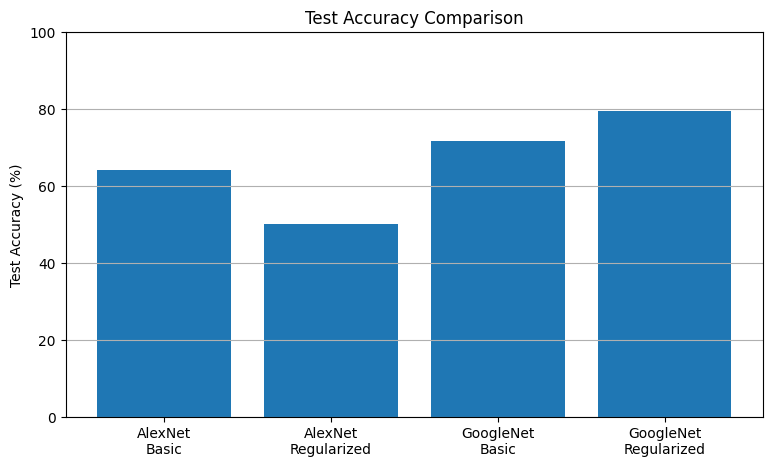

In [22]:
plt.figure(figsize=(9,5))

labels = [
    "AlexNet\nBasic",
    "AlexNet\nRegularized",
    "GoogleNet\nBasic",
    "GoogleNet\nRegularized"
]

values = results["Test Accuracy (%)"].values

plt.bar(labels, values)
plt.ylabel("Test Accuracy (%)")
plt.title("Test Accuracy Comparison")
plt.ylim(0, 100)
plt.grid(axis="y")
plt.show()

# Combined Comparison Graphs

All four experiments plotted together, plus per-class accuracy.

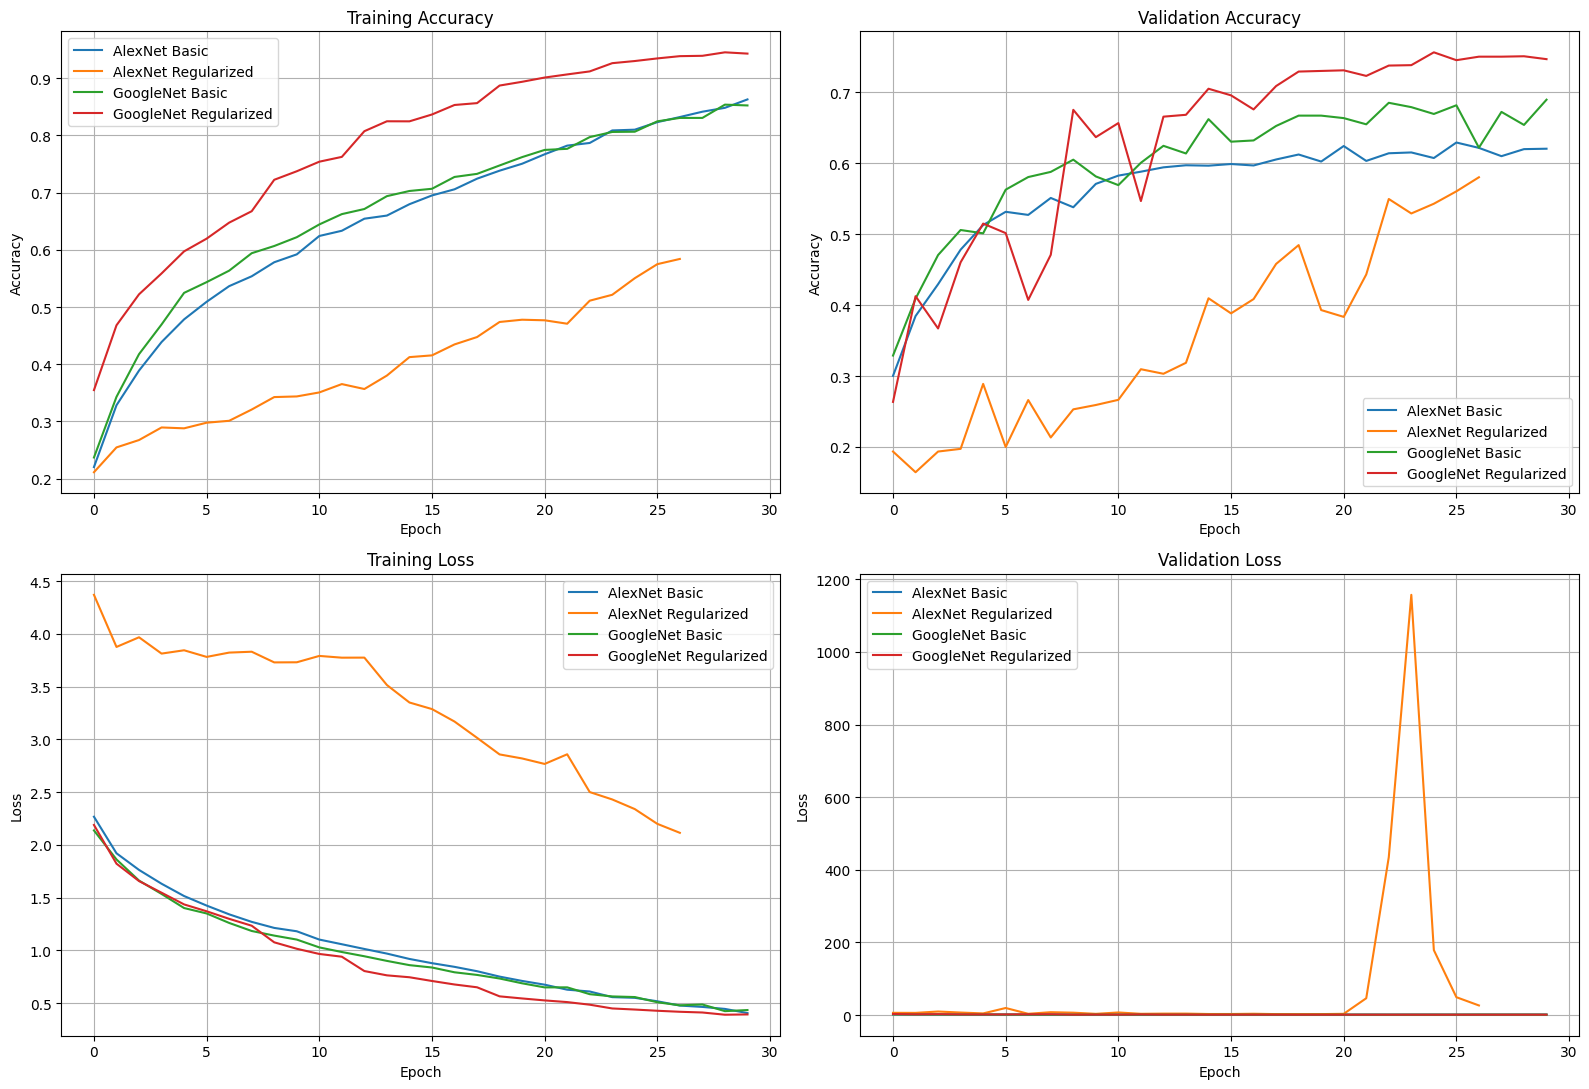

In [23]:
histories = {
    "AlexNet Basic": history_alex_basic,
    "AlexNet Regularized": history_alex_regularized,
    "GoogleNet Basic": history_googlenet_basic,
    "GoogleNet Regularized": history_googlenet_regularized,
}

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for name, h in histories.items():
    axes[0, 0].plot(h.history["accuracy"], label=name)
    axes[0, 1].plot(h.history["val_accuracy"], label=name)
    axes[1, 0].plot(h.history["loss"], label=name)
    axes[1, 1].plot(h.history["val_loss"], label=name)

titles = ["Training Accuracy", "Validation Accuracy", "Training Loss", "Validation Loss"]
for ax, t in zip(axes.flatten(), titles):
    ax.set_title(t)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(t.split()[-1])
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()

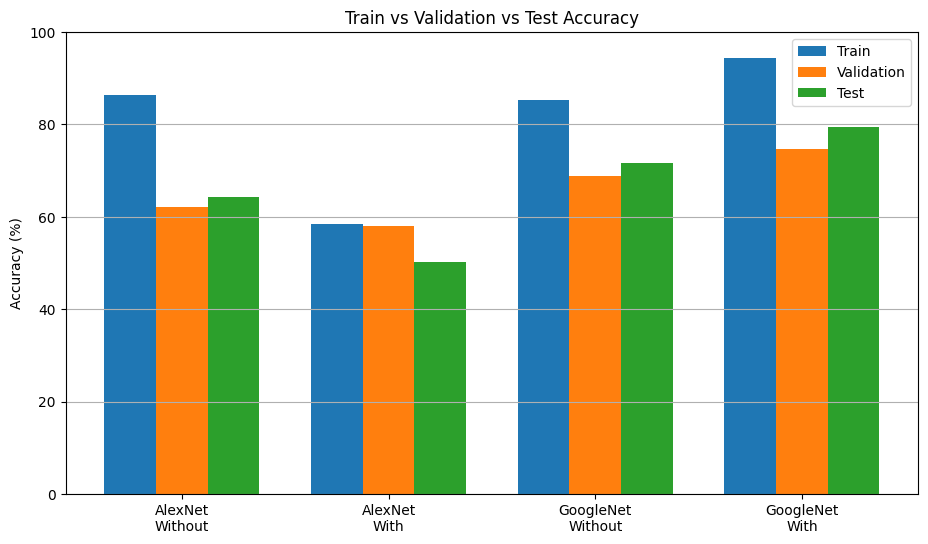

In [24]:
x = np.arange(len(results))
width = 0.25
plt.figure(figsize=(11, 6))
plt.bar(x - width, results["Final Training Accuracy (%)"], width, label="Train")
plt.bar(x, results["Final Validation Accuracy (%)"], width, label="Validation")
plt.bar(x + width, results["Test Accuracy (%)"], width, label="Test")
plt.xticks(x, [f"{m}\n{t.replace(' Overfitting Reduction','')}" for m, t in zip(results["Model"], results["Technique"])])
plt.ylabel("Accuracy (%)")
plt.title("Train vs Validation vs Test Accuracy")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y")
plt.show()

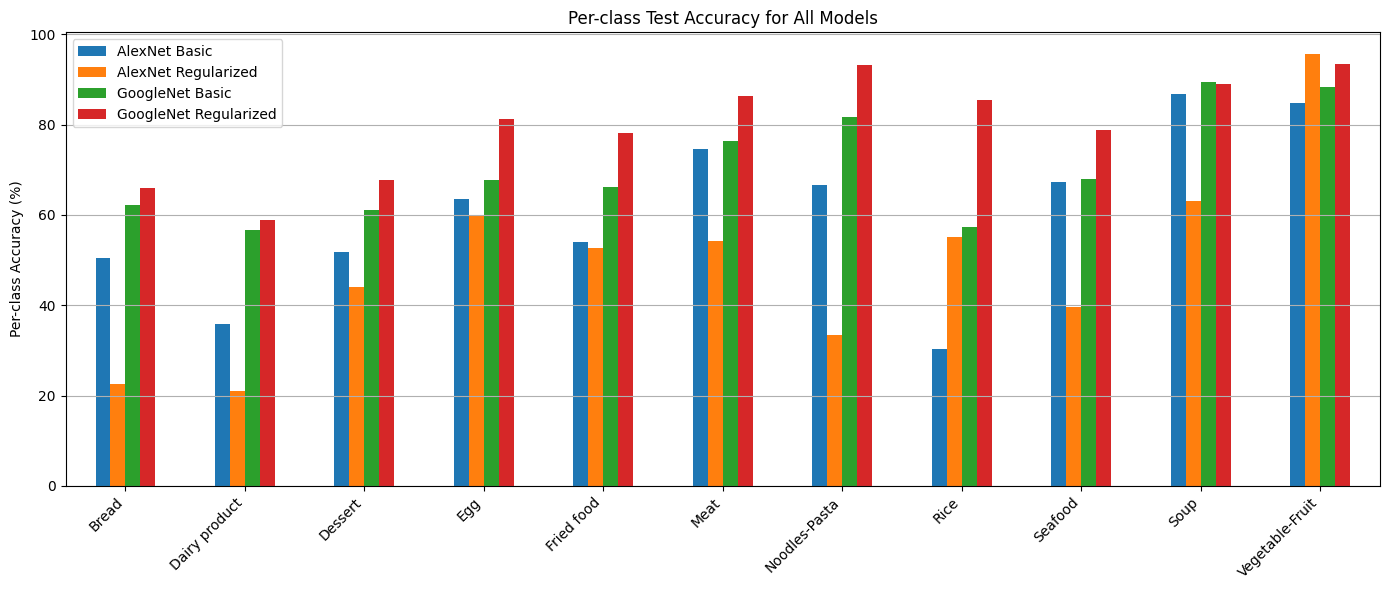

,AlexNet Basic,AlexNet Regularized,GoogleNet Basic,GoogleNet Regularized
Bread,50.5,22.6,62.2,66.0
Dairy product,35.8,20.9,56.8,58.8
Dessert,51.8,44.0,61.0,67.8
Egg,63.6,60.0,67.8,81.2
Fried food,54.0,52.6,66.2,78.0
Meat,74.5,54.2,76.4,86.3
Noodles-Pasta,66.7,33.3,81.6,93.2
Rice,30.2,55.2,57.3,85.4
Seafood,67.3,39.6,68.0,78.9
Soup,86.8,63.2,89.4,89.0


In [25]:
class_labels = list(test_generator.class_indices.keys())
per_class = pd.DataFrame({
    "AlexNet Basic": cm_alex_basic.diagonal() / cm_alex_basic.sum(axis=1),
    "AlexNet Regularized": cm_alex_reg.diagonal() / cm_alex_reg.sum(axis=1),
    "GoogleNet Basic": cm_goog_basic.diagonal() / cm_goog_basic.sum(axis=1),
    "GoogleNet Regularized": cm_goog_reg.diagonal() / cm_goog_reg.sum(axis=1),
}, index=class_labels) * 100

per_class.plot(kind="bar", figsize=(14, 6))
plt.ylabel("Per-class Accuracy (%)")
plt.title("Per-class Test Accuracy for All Models")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

display(per_class.round(1))

# Conclusion

AlexNet and a GoogleNet/Inception-style CNN were implemented on Food-11. Each architecture was evaluated with and without deliberate overfitting-reduction techniques.

Accuracy was improved without changing the model architectures, by tuning hyperparameters: more epochs (the earlier 15-epoch runs were still underfitting), a larger input size, a higher learning rate for BatchNorm models, a weaker L2 penalty, He initialization, milder augmentation, and more patient early stopping / learning-rate scheduling.

The notebook reports training accuracy, validation accuracy, loss curves, and test accuracy. Overfitting-reduction techniques include data augmentation, dropout, batch normalization, L2 regularization, early stopping, and adaptive learning-rate reduction.

The final interpretation should be based on the measured curves and test results rather than assuming that a technique always improves accuracy.